In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from scipy.stats import kurtosis, skew
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils import resample
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score
from skimage.feature import hog
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
import joblib

In [21]:
from google.colab import drive
drive.mount('/content/drive')
train_dir = '/content/drive/MyDrive/train-emotions'
test_dir = '/content/drive/MyDrive/test-emotions'

train_dir

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


'/content/drive/MyDrive/train-emotions'

Total de imágenes en train: 10694
Imágenes por emoción en train: {'angry': 3480, 'happy': 7214}
Total de imágenes en test: 2731
Imágenes por emoción en test: {'angry': 957, 'happy': 1774}


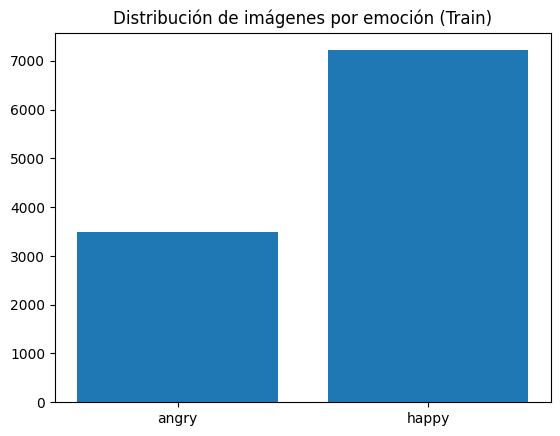

In [ ]:
#@title CANTIDAD DE IMAGENES DEL DATASET
def count_images_in_folders(base_path):
    emotions = ['angry', 'happy']
    total_count = 0
    count_per_emotion = {}

    for emotion in emotions:
        emotion_path = os.path.join(base_path, emotion)
        count = len([img for img in os.listdir(emotion_path) if img.endswith('.jpg')])
        count_per_emotion[emotion] = count
        total_count += count

    return total_count, count_per_emotion

train_total, train_counts = count_images_in_folders(train_dir)
test_total, test_counts = count_images_in_folders(test_dir)

print(f"Total de imágenes en train: {train_total}")
print(f"Imágenes por emoción en train: {train_counts}")

print(f"Total de imágenes en test: {test_total}")
print(f"Imágenes por emoción en test: {test_counts}")

# Gráfico de barras para el balance de clases
labels = list(train_counts.keys())
values = list(train_counts.values())

plt.bar(labels, values)
plt.title('Distribución de imágenes por emoción (Train)')
plt.show()

In [ ]:
#@title ELIMINAR IMAGENES NULAS
# Función para verificar si una imagen es completamente negra
def is_black_image(image):
    return np.max(image) == np.min(image)

# Función para eliminar las imágenes negras de una carpeta
def remove_black_images(folder_path):
    emotions = ['angry', 'happy']  # Subcarpetas de emociones
    total_removed = 0  # Contador de imágenes eliminadas

    # Iterar sobre las carpetas de emociones
    for emotion in emotions:
        emotion_folder = os.path.join(folder_path, emotion)

        if not os.path.exists(emotion_folder):
            print(f"La carpeta {emotion_folder} no existe.")
            continue

        print(f"Procesando carpeta: {emotion_folder}")

        # Iterar sobre las imágenes en la carpeta
        for filename in os.listdir(emotion_folder):
            image_path = os.path.join(emotion_folder, filename)

            if filename.endswith('.jpg') or filename.endswith('.png'):
                # Leer la imagen en escala de grises
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                # Verificar si la imagen es negra
                if is_black_image(image):
                    os.remove(image_path)  # Eliminar la imagen negra
                    total_removed += 1
                    print(f"Eliminada imagen negra: {filename}")

    print(f"Total de imágenes negras eliminadas en {folder_path}: {total_removed}")

# Eliminar imágenes negras de los conjuntos train y test
remove_black_images(train_dir)
remove_black_images(test_dir)

Procesando carpeta: /content/drive/MyDrive/train-emotions/angry
Procesando carpeta: /content/drive/MyDrive/train-emotions/happy
Total de imágenes negras eliminadas en /content/drive/MyDrive/train-emotions: 0
Procesando carpeta: /content/drive/MyDrive/test-emotions/angry
Procesando carpeta: /content/drive/MyDrive/test-emotions/happy
Total de imágenes negras eliminadas en /content/drive/MyDrive/test-emotions: 0


In [ ]:
#@title Cargar imagenes y devolverlas con las etiquetas
def load_images(train_folder, test_folder, num_train_images_per_class, num_test_images_per_class,target_size):
    def load_from_folder(folder, num_images):
        images = []
        labels = []
        count_angry = 0
        count_happy = 0

        # Definir las etiquetas para las carpetas
        emotion_folders = {'angry': 0, 'happy': 1}

        for emotion, label in emotion_folders.items():
            emotion_folder = os.path.join(folder, emotion)

            # Comprobar si la carpeta existe
            if not os.path.exists(emotion_folder):
                print(f"Carpeta no encontrada: {emotion_folder}")
                continue

            image_files = os.listdir(emotion_folder)

            # Limitar el número de imágenes a cargar
            image_files = image_files[:num_images]  # Asegurarse de no exceder el número solicitado

            for filename in image_files:
                if filename.lower().endswith(('.jpg', '.jpeg', '.png')):  # Aceptar múltiples formatos
                    image_path = os.path.join(emotion_folder, filename)
                    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                    if img is not None:
                        # Redimensionar la imagen
                        img_resized = cv2.resize(img, target_size)
                        images.append(img_resized)
                        labels.append(label)

                        # Contar imágenes cargadas
                        if emotion == 'angry':
                            count_angry += 1
                        elif emotion == 'happy':
                            count_happy += 1

        return np.array(images), np.array(labels), count_angry, count_happy

    # Cargar imágenes de entrenamiento (train)
    train_images, train_labels, count_train_angry, count_train_happy = load_from_folder(train_folder, num_train_images_per_class)

    # Cargar imágenes de prueba (test)
    test_images, test_labels, count_test_angry, count_test_happy = load_from_folder(test_folder, num_test_images_per_class)

    # Información sobre el conjunto cargado
    print(f"\nTrain - Imágenes 'angry': {count_train_angry}, Imágenes 'happy': {count_train_happy}")
    print(f"Test - Imágenes 'angry': {count_test_angry}, Imágenes 'happy': {count_test_happy}")

    return (train_images, train_labels), (test_images, test_labels)

# Ejemplo de uso
num_train_images_per_class = 2500  # Número de imágenes a cargar por clase en el conjunto de entrenamiento
num_test_images_per_class = 500   # Número de imágenes a cargar por clase en el conjunto de prueba
target_size = (64, 64)  # Tamaño al que se redimensionarán las imágenes

(train_images, train_labels), (test_images, test_labels) = load_images(train_dir, test_dir, num_train_images_per_class, num_test_images_per_class,target_size)

print(f"\nCargadas {len(train_images)} imágenes de entrenamiento y {len(test_images)} imágenes de prueba con tamaño {target_size}.")


Train - Imágenes 'angry': 2500, Imágenes 'happy': 2500
Test - Imágenes 'angry': 500, Imágenes 'happy': 500

Cargadas 5000 imágenes de entrenamiento y 1000 imágenes de prueba con tamaño (64, 64).


In [ ]:
# def apply_filters(images, labels):
#     filtered_images = {'angry': [], 'happy': []}

#     for img, label in zip(images, labels):
#         # Filtro de Gaussian Blur
#         img_blurred = cv2.GaussianBlur(img, (5, 5), 0)

#         # Filtro de Canny para detección de bordes
#         # img_edges = cv2.Canny(img_blurred, 100, 200)

#         sobelx = cv2.Sobel(img_normalized, cv2.CV_64F, 1, 0, ksize=5)
#         sobely = cv2.Sobel(img_normalized, cv2.CV_64F, 0, 1, ksize=5)
#         img_edges = cv2.magnitude(sobelx, sobely)  # Magnitud de los bordes

#         # Normalización de la imagen
#         img_normalized = cv2.normalize(img_edges, None, 0, 255, cv2.NORM_MINMAX)



#         # Guardar la imagen procesada en la clase correspondiente
#         if label == 0:  # 'angry'
#             filtered_images['angry'].append(img_normalized)
#         elif label == 1:  # 'happy'
#             filtered_images['happy'].append(img_normalized)

#     return filtered_images

# def apply_filters(images, labels):
#     filtered_images = {'angry': [], 'happy': []}

#     for img, label in zip(images, labels):
#         # Filtro Bilateral para suavizado
#         img_bilateral = cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)

#         # Aplicación del filtro Sobel para detectar bordes en ambas direcciones (x e y)
#         sobelx = cv2.Sobel(img_bilateral, cv2.CV_64F, 1, 0, ksize=5)  # Derivada en x
#         sobely = cv2.Sobel(img_bilateral, cv2.CV_64F, 0, 1, ksize=5)  # Derivada en y

#         # Magnitud de los bordes combinados
#         img_edges = cv2.magnitude(sobelx, sobely)

#         # Normalización de la imagen
#         img_normalized = cv2.normalize(img_edges, None, 0, 255, cv2.NORM_MINMAX)

#         # Guardar la imagen procesada en la clase correspondiente
#         if label == 0:  # 'angry'
#             filtered_images['angry'].append(img_normalized)
#         elif label == 1:  # 'happy'
#             filtered_images['happy'].append(img_normalized)

#     return filtered_images

# Función para aplicar filtros a las imágenes
def apply_filters(images, labels):
    filtered_images = {'angry': [], 'happy': []}

    for img, label in zip(images, labels):
        # Filtro de Gaussian Blur
        img_blurred = cv2.GaussianBlur(img, (5, 5), 0)

        # Filtro de Canny para detección de bordes
        img_edges = cv2.Canny(img_blurred, 100, 200)

        # Normalización de la imagen
        img_normalized = cv2.normalize(img_edges, None, 0, 255, cv2.NORM_MINMAX)

        # Guardar la imagen procesada en la clase correspondiente
        if label == 0:  # 'angry'
            filtered_images['angry'].append(img_normalized)
        elif label == 1:  # 'happy'
            filtered_images['happy'].append(img_normalized)

    return filtered_images

# Función para extraer características de las imágenes filtradas
def extract_features(images):
    features = []

    for img in images:
        # 1. Histogram of Oriented Gradients (HOG)
        hog_features = hog(img, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=False)

        # 2. Estadísticas básicas
        mean_val = np.mean(img)
        var_val = np.var(img)
        kurt_val = kurtosis(img, axis=None)
        skew_val = skew(img, axis=None)

        # 3. Momentos de Hu
        moments = cv2.HuMoments(cv2.moments(img)).flatten()

        # Combinar todas las características
        combined_features = np.hstack((hog_features, mean_val, var_val, moments))
        features.append(combined_features)

    return np.array(features)

# Aplicar filtros a las imágenes de entrenamiento
filtered_train_images = apply_filters(train_images, train_labels)
filtered_test_images = apply_filters(test_images, test_labels)

# Extraer características para las imágenes de entrenamiento y prueba filtradas
train_happy_features = extract_features(filtered_train_images['happy'])
train_angry_features = extract_features(filtered_train_images['angry'])

test_happy_features = extract_features(filtered_test_images['happy'])
test_angry_features = extract_features(filtered_test_images['angry'])

# Ver las dimensiones de las características extraídas
print(f"Características de entrenamiento 'happy': {train_happy_features.shape}")
print(f"Características de entrenamiento 'angry': {train_angry_features.shape}")
print(f"Características de prueba 'happy': {test_happy_features.shape}")
print(f"Características de prueba 'angry': {test_angry_features.shape}")

# Combinar características y etiquetas para entrenamiento
train_features = np.vstack((train_happy_features, train_angry_features))
train_labels_combined = np.array([1] * train_happy_features.shape[0] + [0] * train_angry_features.shape[0])

# Combinar características y etiquetas para prueba
test_features = np.vstack((test_happy_features, test_angry_features))
test_labels_combined = np.array([1] * test_happy_features.shape[0] + [0] * test_angry_features.shape[0])

print(f"Tamaño de características combinadas para entrenamiento: {train_features.shape}")
print(f"Tamaño de etiquetas para entrenamiento: {train_labels_combined.shape}")
print(f"Tamaño de características combinadas para prueba: {test_features.shape}")
print(f"Tamaño de etiquetas para prueba: {test_labels_combined.shape}")


Características de entrenamiento 'happy': (2500, 1773)
Características de entrenamiento 'angry': (2500, 1773)
Características de prueba 'happy': (500, 1773)
Características de prueba 'angry': (500, 1773)
Tamaño de características combinadas para entrenamiento: (5000, 1773)
Tamaño de etiquetas para entrenamiento: (5000,)
Tamaño de características combinadas para prueba: (1000, 1773)
Tamaño de etiquetas para prueba: (1000,)


Precisión del modelo SVM:
Precisión: 0.92
Matriz de confusión:
[[686  46]
 [ 72 696]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.91      0.94      0.92       732
           1       0.94      0.91      0.92       768

    accuracy                           0.92      1500
   macro avg       0.92      0.92      0.92      1500
weighted avg       0.92      0.92      0.92      1500



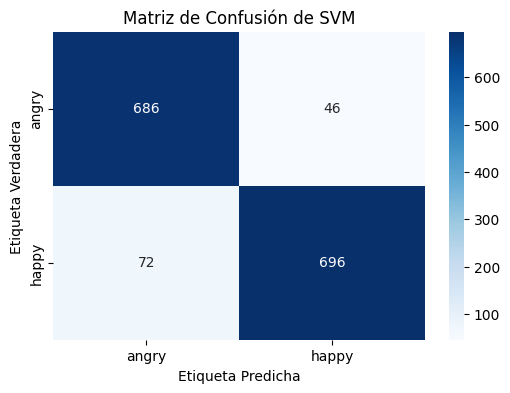

['modelo_svm.pkl']

In [16]:
#@title ENTRENAR SVM

def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['angry', 'happy'], yticklabels=['angry', 'happy'])
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.title(title)
    plt.show()

# Dividir el conjunto de datos en entrenamiento y validación
X_train, X_val, y_train, y_val = train_test_split(train_features, train_labels_combined, test_size=0.3, random_state=42)

# Crear el clasificador
model = SVC(kernel='linear')  # Puedes ajustar el kernel según sea necesario

# Entrenar el modelo
model.fit(X_train, y_train)

# Hacer predicciones en el conjunto de validación
y_pred = model.predict(X_val)

# Mostrar los resultados
svm_accuracy = accuracy_score(y_val, y_pred)
print("Precisión del modelo SVM:")
print(f"Precisión: {svm_accuracy:.2f}")

# Evaluar el modelo
print("Matriz de confusión:")
svm_conf_matrix = confusion_matrix(y_val, y_pred)
print(svm_conf_matrix)

print("\nReporte de clasificación:")
print(classification_report(y_val, y_pred))

plot_confusion_matrix(svm_conf_matrix, "Matriz de Confusión de SVM")

# Guardar el modelo entrenado
joblib.dump(model, 'modelo_svm.pkl')  # Guarda el modelo en un archivo


Precisión del modelo SVM:
Precisión: 0.78

Reporte de clasificación para KNN:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       732
           1       0.81      0.73      0.77       768

    accuracy                           0.78      1500
   macro avg       0.78      0.78      0.78      1500
weighted avg       0.78      0.78      0.78      1500


Matriz de confusión para KNN:
[[602 130]
 [204 564]]


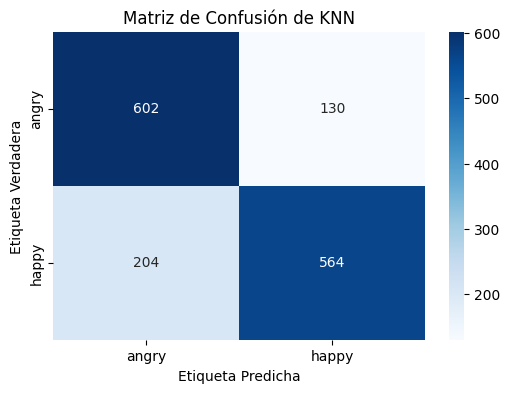

['modelo_knn.pkl']

In [17]:
def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['angry', 'happy'], yticklabels=['angry', 'happy'])
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.title(title)
    plt.show()

X_train, X_val, y_train, y_val = train_test_split(train_features, train_labels_combined, test_size=0.3, random_state=42)

# Definir el modelo KNN con un número fijo de vecinos (ejemplo: 5 vecinos)
knn_model = KNeighborsClassifier(n_neighbors=5, weights='uniform', metric='euclidean')

# Entrenar el modelo KNN con los datos de entrenamiento
knn_model.fit(X_train, y_train)

# Realizar predicciones sobre el conjunto de prueba
y_pred_knn = knn_model.predict(X_val)

#Mostrar los resultados
knn_accuracy = accuracy_score(y_val, y_pred_knn)
print("Precisión del modelo SVM:")
print(f"Precisión: {knn_accuracy:.2f}")

# Mostrar el reporte de clasificación
print("\nReporte de clasificación para KNN:")
print(classification_report(y_val, y_pred_knn))

# Mostrar la matriz de confusión
print("\nMatriz de confusión para KNN:")
knn_conf_matrix = confusion_matrix(y_val, y_pred_knn)
print(knn_conf_matrix)

plot_confusion_matrix(knn_conf_matrix, "Matriz de Confusión de KNN")

# Para el modelo KNN
joblib.dump(knn_model, 'modelo_knn.pkl')

Precisión del modelo Regresion Log:
Precisión: 0.92

Reporte de clasificación para Regresión Logística:
              precision    recall  f1-score   support

           0       0.89      0.96      0.92       732
           1       0.96      0.89      0.92       768

    accuracy                           0.92      1500
   macro avg       0.92      0.92      0.92      1500
weighted avg       0.93      0.92      0.92      1500


Matriz de confusión para Regresión Logística:
[[700  32]
 [ 83 685]]


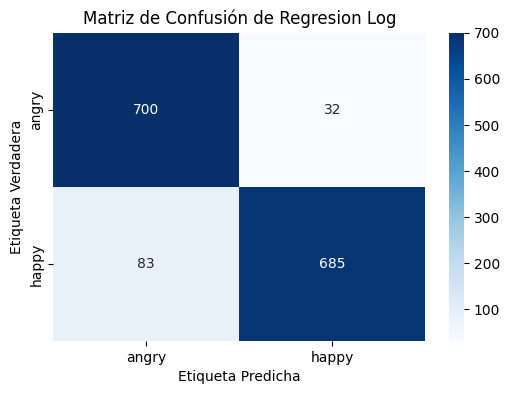

['modelo_reg_log.pkl']

In [18]:
#@title ENTRENAR REGRESION LOGISTICA

X_train, X_val, y_train, y_val = train_test_split(train_features, train_labels_combined, test_size=0.3, random_state=42)

# Definir el modelo de Regresión Logística
log_reg = LogisticRegression(solver='liblinear', max_iter=1000)

# Entrenar el modelo con los datos de entrenamiento
log_reg.fit(X_train, y_train)

# Realizar predicciones sobre el conjunto de prueba
y_pred_log_reg = log_reg.predict(X_val)

# Mostrar los resultados
log_reg_accuracy = accuracy_score(y_val, y_pred_log_reg)
print("Precisión del modelo Regresion Log:")
print(f"Precisión: {log_reg_accuracy:.2f}")

# Mostrar el reporte de clasificación
print("\nReporte de clasificación para Regresión Logística:")
print(classification_report(y_val, y_pred_log_reg))

# Mostrar la matriz de confusión
print("\nMatriz de confusión para Regresión Logística:")
log_reg_matrix = confusion_matrix(y_val, y_pred_log_reg)
print(log_reg_matrix)


plot_confusion_matrix(log_reg_matrix, "Matriz de Confusión de Regresion Log")

# Para el modelo KNN
joblib.dump(log_reg, 'modelo_reg_log.pkl')